In [3]:
!pip install pandas numpy matplotlib seaborn


In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use("default")
sns.set(style="whitegrid")

pd.set_option("display.max_columns", None)


In [6]:
import pandas as pd

file_path = r"C:\Users\ngosa\Desktop\GITHUB ROADMAP\Hotel Revenue forcasting Model\hotel_bookings demand.csv"

df = pd.read_csv(file_path)
df.head()


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,3,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,4,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Direct,Direct,0,0,0,A,C,0,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Corporate,Corporate,0,0,0,A,A,0,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,0.0,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 
plt.style.use("default")               # Matplotlib default
sns.set(style="whitegrid")             

# Font settings
plt.rcParams["font.family"] = "DejaVu Sans"
plt.rcParams["font.size"] = 11         
plt.rcParams["axes.titlesize"] = 12    
plt.rcParams["axes.labelsize"] = 11
plt.rcParams["xtick.labelsize"] = 10
plt.rcParams["ytick.labelsize"] = 10

# COLORS
COLOR_BLUE = "#1f77b4"     # Matplotlib default blue
COLOR_ORANGE = "#ff7f0e"   # Matplotlib default orange
COLOR_RED = "#d62728"      # Used for block highlights
COLOR_GREEN = "#2ca02c"    # Rarely used but part of default palette

pd.set_option("display.max_columns", None)


In [9]:
df["arrival_date"] = pd.to_datetime(
    df["arrival_date_year"].astype(str) + "-" +
    df["arrival_date_month"].astype(str) + "-" +
    df["arrival_date_day_of_month"].astype(str)
)


In [10]:
df_stayed = df[df["reservation_status"] == "Check-Out"].copy()

df_stayed["booking_date"] = df_stayed["arrival_date"] - pd.to_timedelta(df_stayed["lead_time"], unit="D")
df_stayed["lead_time_days"] = (df_stayed["arrival_date"] - df_stayed["booking_date"]).dt.days


In [11]:
n_stayed = len(df_stayed)
median_lead = df_stayed["lead_time_days"].median()
mean_lead = df_stayed["lead_time_days"].mean()

same_day = (df_stayed["lead_time_days"] == 0).mean() * 100
within_7 = (df_stayed["lead_time_days"] <= 7).mean() * 100
over_180 = (df_stayed["lead_time_days"] > 180).mean() * 100

n_stayed, median_lead, mean_lead, same_day, within_7, over_180


(75166,
 45.0,
 79.98468722560732,
 7.8692493946731235,
 23.739456669238752,
 14.122076470744751)

In [12]:
# SECTION 03 — Busiest Arrival Date

busiest_date = pd.to_datetime("2015-12-05")
df_peak = df_stayed[df_stayed["arrival_date"] == busiest_date].copy()

len(df_peak)


255

In [13]:
df_peak_sorted = df_peak.sort_values("lead_time_days")
df_peak_sorted["cum_bookings"] = np.arange(1, len(df_peak_sorted) + 1)


In [16]:
median_peak_lead = df_peak["lead_time_days"].median()
on_books_60 = (df_peak["lead_time_days"] >= 60).mean() * 100
on_books_30 = (df_peak["lead_time_days"] >= 30).mean() * 100

median_peak_lead, on_books_60, on_books_30


(19.0, 21.568627450980394, 45.88235294117647)

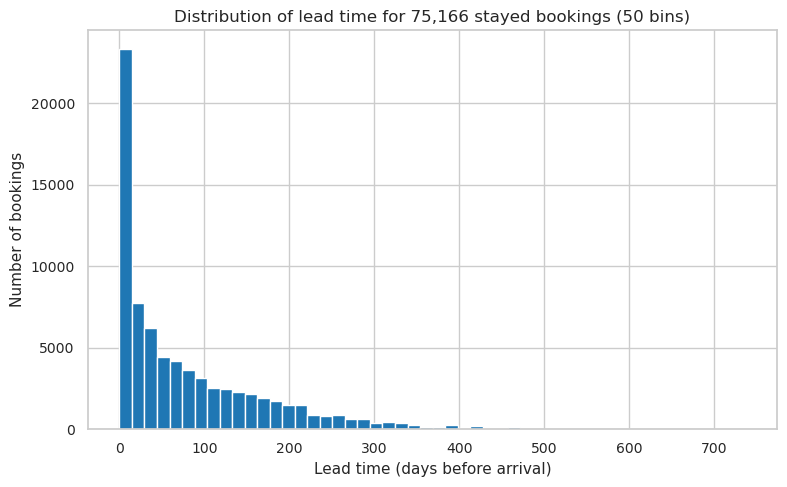

In [17]:
plt.figure(figsize=(8,5))

plt.hist(
    df_stayed["lead_time_days"],
    bins=50,
    color=COLOR_BLUE,
    edgecolor="white"
)

plt.title("Distribution of lead time for 75,166 stayed bookings (50 bins)")
plt.xlabel("Lead time (days before arrival)")
plt.ylabel("Number of bookings")

plt.tight_layout()
plt.show()


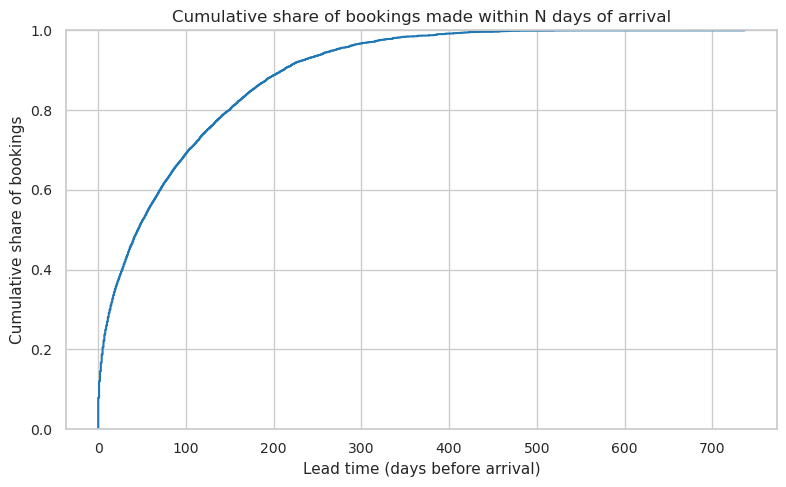

In [18]:
lt_sorted = np.sort(df_stayed["lead_time_days"])
cum = np.arange(1, len(lt_sorted)+1) / len(lt_sorted)

plt.figure(figsize=(8,5))

plt.plot(
    lt_sorted,
    cum,
    color=COLOR_BLUE
)

plt.title("Cumulative share of bookings made within N days of arrival")
plt.xlabel("Lead time (days before arrival)")
plt.ylabel("Cumulative share of bookings")
plt.ylim(0, 1)

plt.tight_layout()
plt.show()


In [19]:
median_lt = df_stayed["lead_time_days"].median()
mean_lt = df_stayed["lead_time_days"].mean()

same_day = (df_stayed["lead_time_days"] == 0).mean() * 100
within_7 = (df_stayed["lead_time_days"] <= 7).mean() * 100
within_30 = (df_stayed["lead_time_days"] <= 30).mean() * 100
within_60 = (df_stayed["lead_time_days"] <= 60).mean() * 100
within_90 = (df_stayed["lead_time_days"] <= 90).mean() * 100
within_180 = (df_stayed["lead_time_days"] <= 180).mean() * 100

longest = df_stayed["lead_time_days"].max()

(
    median_lt,
    mean_lt,
    same_day,
    within_7,
    within_30,
    within_60,
    within_90,
    within_180,
    longest
)


(45.0,
 79.98468722560732,
 7.8692493946731235,
 23.739456669238752,
 41.93518346060719,
 56.29806029321768,
 66.4303009339329,
 85.87792352925526,
 737)

In [20]:
# Busiest Arrival Date

busiest_date = pd.to_datetime("2015-12-05")
df_peak = df_stayed[df_stayed["arrival_date"] == busiest_date].copy()

len(df_peak)


255

In [21]:
df_peak_sorted = df_peak.sort_values("lead_time_days")
df_peak_sorted["cum_bookings"] = np.arange(1, len(df_peak_sorted) + 1)


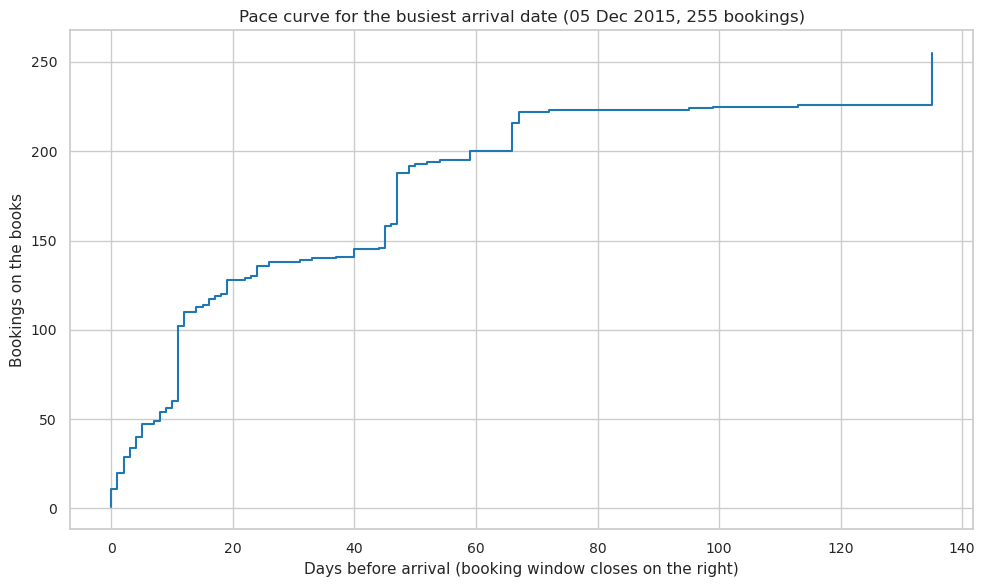

In [22]:
plt.figure(figsize=(10,6))

plt.step(
    df_peak_sorted["lead_time_days"],
    df_peak_sorted["cum_bookings"],
    where="post",
    color=COLOR_BLUE
)

plt.title("Pace curve for the busiest arrival date (05 Dec 2015, 255 bookings)")
plt.xlabel("Days before arrival (booking window closes on the right)")
plt.ylabel("Bookings on the books")

plt.tight_layout()
plt.show()


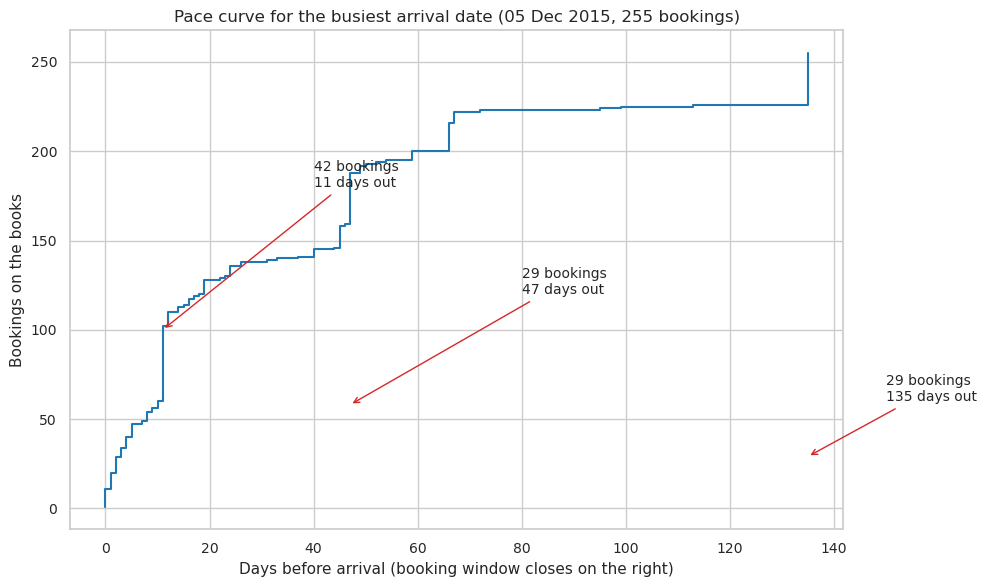

In [23]:
plt.figure(figsize=(10,6))

plt.step(
    df_peak_sorted["lead_time_days"],
    df_peak_sorted["cum_bookings"],
    where="post",
    color=COLOR_BLUE
)

# Annotate the three blocks
plt.annotate("29 bookings\n135 days out",
             xy=(135, 29), xytext=(150, 60),
             arrowprops=dict(arrowstyle="->", color=COLOR_RED),
             fontsize=10)

plt.annotate("29 bookings\n47 days out",
             xy=(47, 58), xytext=(80, 120),
             arrowprops=dict(arrowstyle="->", color=COLOR_RED),
             fontsize=10)

plt.annotate("42 bookings\n11 days out",
             xy=(11, 100), xytext=(40, 180),
             arrowprops=dict(arrowstyle="->", color=COLOR_RED),
             fontsize=10)

plt.title("Pace curve for the busiest arrival date (05 Dec 2015, 255 bookings)")
plt.xlabel("Days before arrival (booking window closes on the right)")
plt.ylabel("Bookings on the books")

plt.tight_layout()
plt.show()


In [24]:
median_peak_lead = df_peak["lead_time_days"].median()
on_books_60 = (df_peak["lead_time_days"] >= 60).mean() * 100
on_books_30 = (df_peak["lead_time_days"] >= 30).mean() * 100

median_peak_lead, on_books_60, on_books_30


(19.0, 21.568627450980394, 45.88235294117647)

In [25]:
# Pickup Heatmap

aug_start = pd.to_datetime("2017-08-01")
aug_end   = pd.to_datetime("2017-08-31")

df_aug = df_stayed[
    (df_stayed["arrival_date"] >= aug_start) &
    (df_stayed["arrival_date"] <= aug_end)
].copy()

len(df_aug)


3109

In [ ]:
df_aug["lead_time_cap"] = df_aug["lead_time_days"].clip(upper=120)


In [28]:
pickup_matrix = df_aug.pivot_table(
    index="arrival_date",
    columns="lead_time_cap",
    values="adr",        # use ADR as a dummy numeric column
    aggfunc="count",
    fill_value=0
)


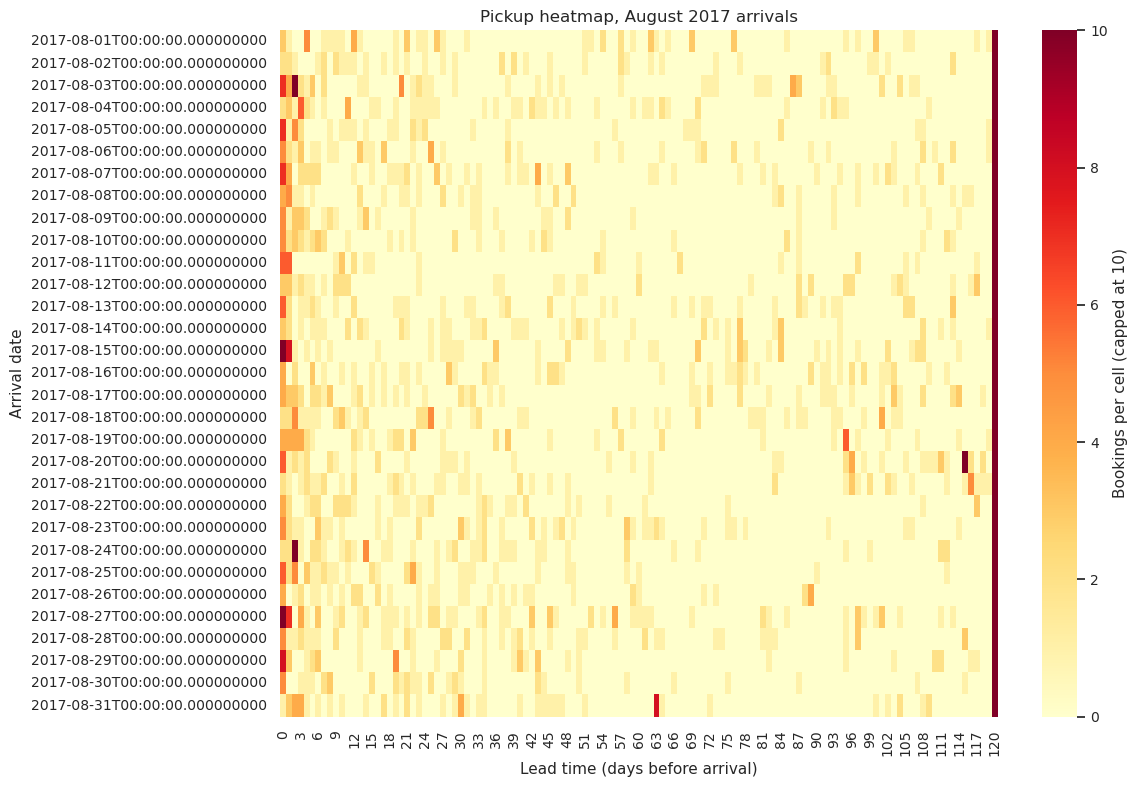

In [29]:
plt.figure(figsize=(12,8))

sns.heatmap(
    pickup_matrix,
    cmap="YlOrRd",
    vmax=10,    # cap color scale at 10
    cbar_kws={"label": "Bookings per cell (capped at 10)"}
)

plt.title("Pickup heatmap, August 2017 arrivals")
plt.xlabel("Lead time (days before arrival)")
plt.ylabel("Arrival date")

plt.tight_layout()
plt.show()


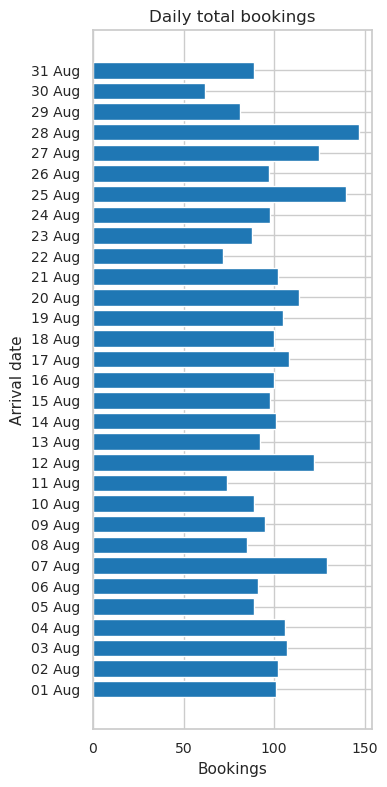

In [30]:
daily_totals = df_aug.groupby("arrival_date").size()

plt.figure(figsize=(4,8))

plt.barh(
    daily_totals.index.strftime("%d %b"),
    daily_totals.values,
    color=COLOR_BLUE
)

plt.title("Daily total bookings")
plt.xlabel("Bookings")
plt.ylabel("Arrival date")

plt.tight_layout()
plt.show()


In [31]:
within_3 = (df_aug["lead_time_days"] <= 3).mean() * 100
within_7 = (df_aug["lead_time_days"] <= 7).mean() * 100
within_120 = (df_aug["lead_time_days"] <= 120).mean() * 100

within_3, within_7, within_120


(11.225474429076874, 14.956577677709875, 51.43132840141524)

In [32]:
df_city = df_stayed[df_stayed["hotel"] == "City Hotel"].copy()
df_resort = df_stayed[df_stayed["hotel"] == "Resort Hotel"].copy()

len(df_city), len(df_resort)


(46228, 28938)

In [33]:
city_lead = df_city["lead_time_days"]
resort_lead = df_resort["lead_time_days"]


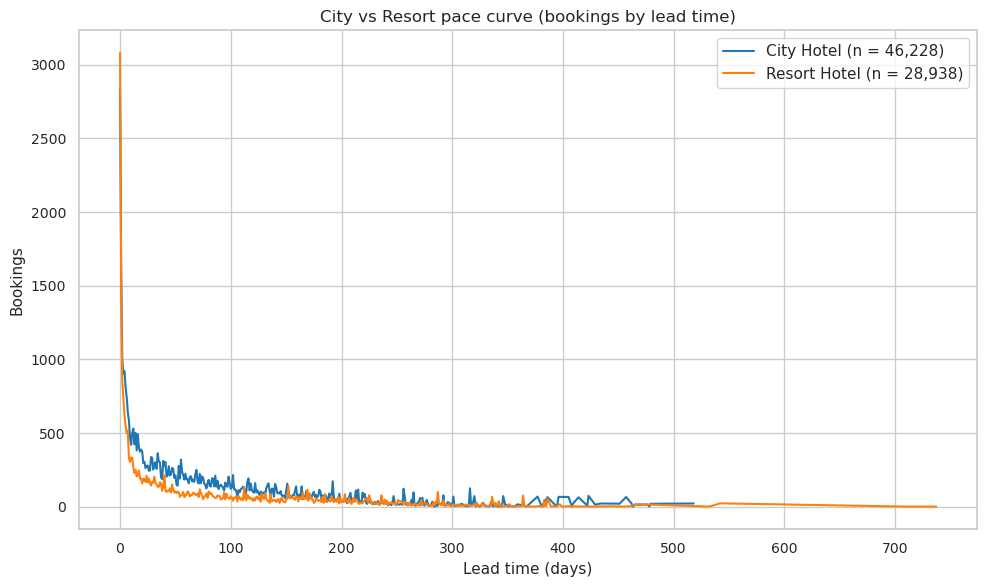

In [34]:
plt.figure(figsize=(10,6))

plt.plot(
    city_lead.value_counts().sort_index(),
    label="City Hotel (n = 46,228)",
    color=COLOR_BLUE
)

plt.plot(
    resort_lead.value_counts().sort_index(),
    label="Resort Hotel (n = 28,938)",
    color=COLOR_ORANGE
)

plt.title("City vs Resort pace curve (bookings by lead time)")
plt.xlabel("Lead time (days)")
plt.ylabel("Bookings")
plt.legend()

plt.tight_layout()
plt.show()


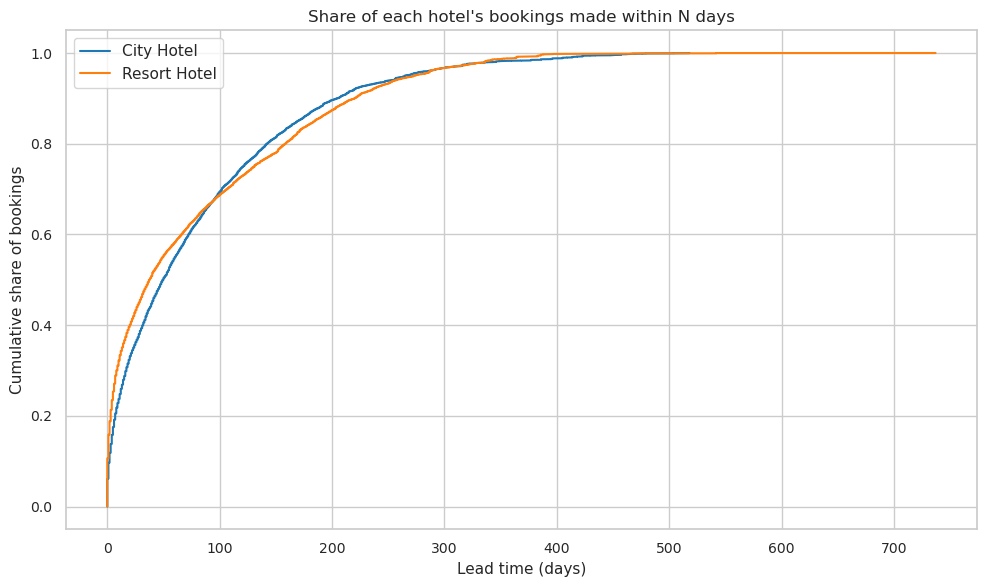

In [36]:
# Compute cumulative distributions
city_sorted = np.sort(city_lead)
resort_sorted = np.sort(resort_lead)

city_cum = np.arange(1, len(city_sorted)+1) / len(city_sorted)
resort_cum = np.arange(1, len(resort_sorted)+1) / len(resort_sorted)

plt.figure(figsize=(10,6))

plt.plot(city_sorted, city_cum, color=COLOR_BLUE, label="City Hotel")
plt.plot(resort_sorted, resort_cum, color=COLOR_ORANGE, label="Resort Hotel")

plt.title("Share of each hotel's bookings made within N days")
plt.xlabel("Lead time (days)")
plt.ylabel("Cumulative share of bookings")
plt.legend()

plt.tight_layout()
plt.show()


In [37]:
metrics_city = {
    "Stayed bookings": len(df_city),
    "Median lead time": city_lead.median(),
    "Mean lead time": city_lead.mean(),
    "Same-day bookings (%)": (city_lead == 0).mean() * 100,
    "Within 7 days (%)": (city_lead <= 7).mean() * 100,
    "Within 30 days (%)": (city_lead <= 30).mean() * 100,
    "Within 90 days (%)": (city_lead <= 90).mean() * 100,
    "More than 180 days (%)": (city_lead > 180).mean() * 100,
    "Average ADR": df_city["adr"].mean()
}

metrics_resort = {
    "Stayed bookings": len(df_resort),
    "Median lead time": resort_lead.median(),
    "Mean lead time": resort_lead.mean(),
    "Same-day bookings (%)": (resort_lead == 0).mean() * 100,
    "Within 7 days (%)": (resort_lead <= 7).mean() * 100,
    "Within 30 days (%)": (resort_lead <= 30).mean() * 100,
    "Within 90 days (%)": (resort_lead <= 90).mean() * 100,
    "More than 180 days (%)": (resort_lead > 180).mean() * 100,
    "Average ADR": df_resort["adr"].mean()
}

metrics_city, metrics_resort


({'Stayed bookings': 46228,
  'Median lead time': 50.0,
  'Mean lead time': 80.70273427360041,
  'Same-day bookings (%)': 6.134810071817945,
  'Within 7 days (%)': 20.526520723371117,
  'Within 30 days (%)': 39.29004066799342,
  'Within 90 days (%)': 66.32344033918837,
  'More than 180 days (%)': 13.17599723111534,
  'Average ADR': 105.74594834299562},
 {'Stayed bookings': 28938,
  'Median lead time': 38.0,
  'Mean lead time': 78.83761835648627,
  'Same-day bookings (%)': 10.639988941875735,
  'Within 7 days (%)': 28.872071324901516,
  'Within 30 days (%)': 46.1607574815122,
  'Within 90 days (%)': 66.60100905383925,
  'More than 180 days (%)': 15.633423180592992,
  'Average ADR': 90.78897055774412})

In [38]:
#  Weekend vs Weekday

# Extract weekday number (Mon=0 ... Sun=6)
df_stayed["weekday"] = df_stayed["arrival_date"].dt.weekday

# Weekend = Fri(4), Sat(5), Sun(6)
df_weekend = df_stayed[df_stayed["weekday"].isin([4,5,6])].copy()
df_weekday = df_stayed[df_stayed["weekday"].isin([0,1,2,3])].copy()

len(df_weekend), len(df_weekday)


(32156, 43010)

In [39]:
weekend_lead = df_weekend["lead_time_days"]
weekday_lead = df_weekday["lead_time_days"]


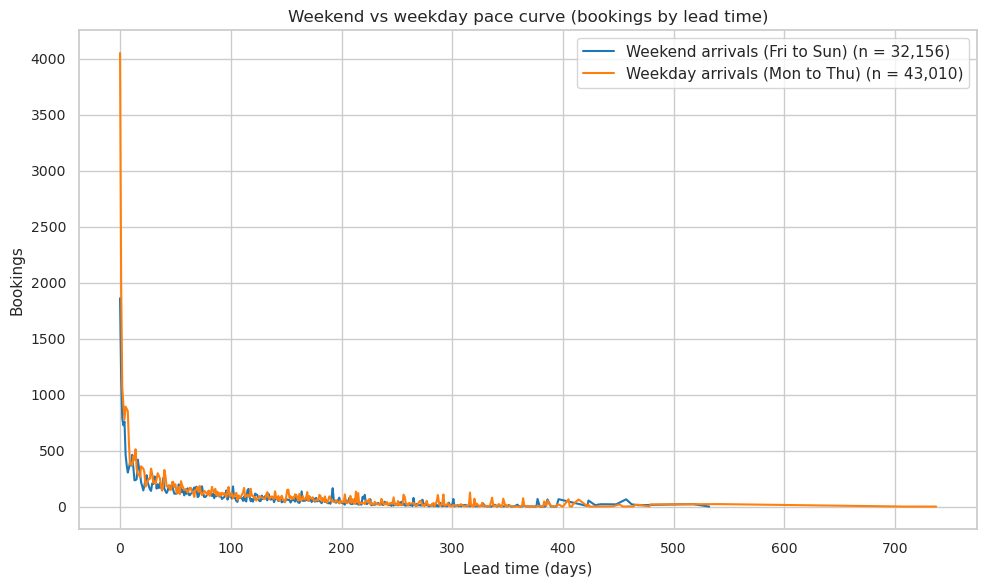

In [40]:
plt.figure(figsize=(10,6))

plt.plot(
    weekend_lead.value_counts().sort_index(),
    label="Weekend arrivals (Fri to Sun) (n = 32,156)",
    color=COLOR_BLUE
)

plt.plot(
    weekday_lead.value_counts().sort_index(),
    label="Weekday arrivals (Mon to Thu) (n = 43,010)",
    color=COLOR_ORANGE
)

plt.title("Weekend vs weekday pace curve (bookings by lead time)")
plt.xlabel("Lead time (days)")
plt.ylabel("Bookings")
plt.legend()

plt.tight_layout()
plt.show()


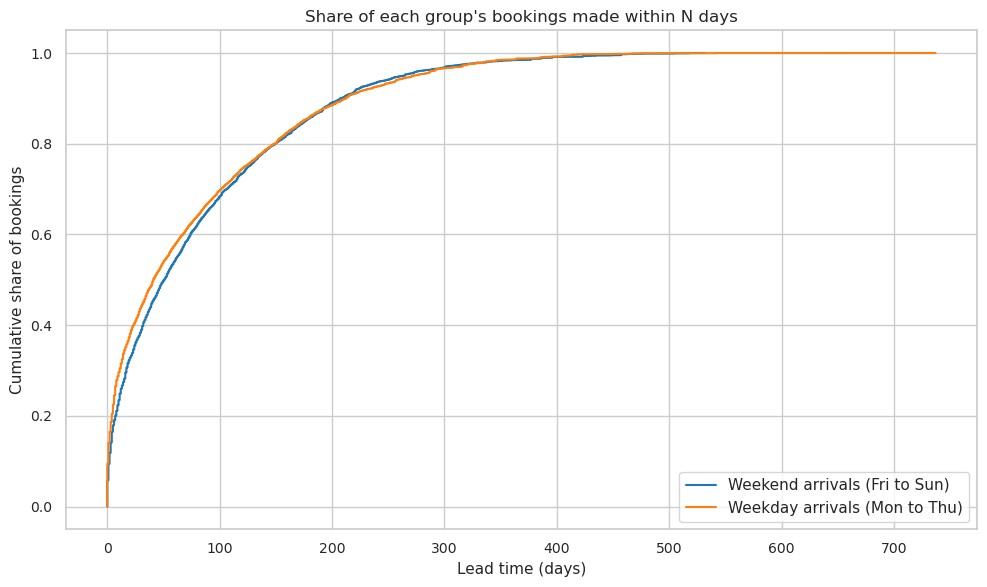

In [41]:
# Compute cumulative distributions
weekend_sorted = np.sort(weekend_lead)
weekday_sorted = np.sort(weekday_lead)

weekend_cum = np.arange(1, len(weekend_sorted)+1) / len(weekend_sorted)
weekday_cum = np.arange(1, len(weekday_sorted)+1) / len(weekday_sorted)

plt.figure(figsize=(10,6))

plt.plot(weekend_sorted, weekend_cum, color=COLOR_BLUE, label="Weekend arrivals (Fri to Sun)")
plt.plot(weekday_sorted, weekday_cum, color=COLOR_ORANGE, label="Weekday arrivals (Mon to Thu)")

plt.title("Share of each group's bookings made within N days")
plt.xlabel("Lead time (days)")
plt.ylabel("Cumulative share of bookings")
plt.legend()

plt.tight_layout()
plt.show()


In [42]:
metrics_weekend = {
    "Stayed bookings": len(df_weekend),
    "Median lead time": weekend_lead.median(),
    "Mean lead time": weekend_lead.mean(),
    "Same-day bookings (%)": (weekend_lead == 0).mean() * 100,
    "Within 7 days (%)": (weekend_lead <= 7).mean() * 100,
    "Within 30 days (%)": (weekend_lead <= 30).mean() * 100,
    "More than 180 days (%)": (weekend_lead > 180).mean() * 100
}

metrics_weekday = {
    "Stayed bookings": len(df_weekday),
    "Median lead time": weekday_lead.median(),
    "Mean lead time": weekday_lead.mean(),
    "Same-day bookings (%)": (weekday_lead == 0).mean() * 100,
    "Within 7 days (%)": (weekday_lead <= 7).mean() * 100,
    "Within 30 days (%)": (weekday_lead <= 30).mean() * 100,
    "More than 180 days (%)": (weekday_lead > 180).mean() * 100
}

metrics_weekend, metrics_weekday


({'Stayed bookings': 32156,
  'Median lead time': 51.0,
  'Mean lead time': 82.17219181490235,
  'Same-day bookings (%)': 5.79052120910561,
  'Within 7 days (%)': 20.011817390222664,
  'Within 30 days (%)': 38.95074014180868,
  'More than 180 days (%)': 14.258614255504416},
 {'Stayed bookings': 43010,
  'Median lead time': 41.0,
  'Mean lead time': 78.34922111136945,
  'Same-day bookings (%)': 9.423389909323413,
  'Within 7 days (%)': 26.526389211811207,
  'Within 30 days (%)': 44.16647291327598,
  'More than 180 days (%)': 14.019995349918624})

In [43]:
segments_main = ["Online TA", "Offline TA/TO", "Direct", "Groups", "Corporate"]

df_seg = df_stayed[df_stayed["market_segment"].isin(segments_main)].copy()


In [44]:
df_online = df_seg[df_seg["market_segment"] == "Online TA"]
df_offline = df_seg[df_seg["market_segment"] == "Offline TA/TO"]
df_direct = df_seg[df_seg["market_segment"] == "Direct"]
df_groups = df_seg[df_seg["market_segment"] == "Groups"]
df_corp = df_seg[df_seg["market_segment"] == "Corporate"]


In [45]:
lead_online = df_online["lead_time_days"]
lead_offline = df_offline["lead_time_days"]
lead_direct = df_direct["lead_time_days"]
lead_groups = df_groups["lead_time_days"]
lead_corp = df_corp["lead_time_days"]


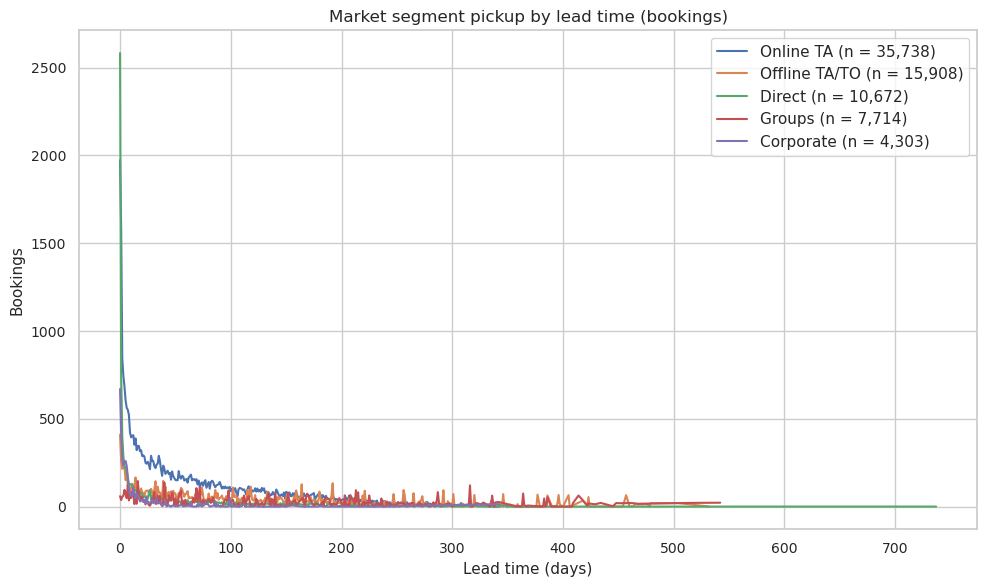

In [46]:
plt.figure(figsize=(10,6))

plt.plot(lead_online.value_counts().sort_index(), label="Online TA (n = 35,738)")
plt.plot(lead_offline.value_counts().sort_index(), label="Offline TA/TO (n = 15,908)")
plt.plot(lead_direct.value_counts().sort_index(), label="Direct (n = 10,672)")
plt.plot(lead_groups.value_counts().sort_index(), label="Groups (n = 7,714)")
plt.plot(lead_corp.value_counts().sort_index(), label="Corporate (n = 4,303)")

plt.title("Market segment pickup by lead time (bookings)")
plt.xlabel("Lead time (days)")
plt.ylabel("Bookings")
plt.legend()

plt.tight_layout()
plt.show()


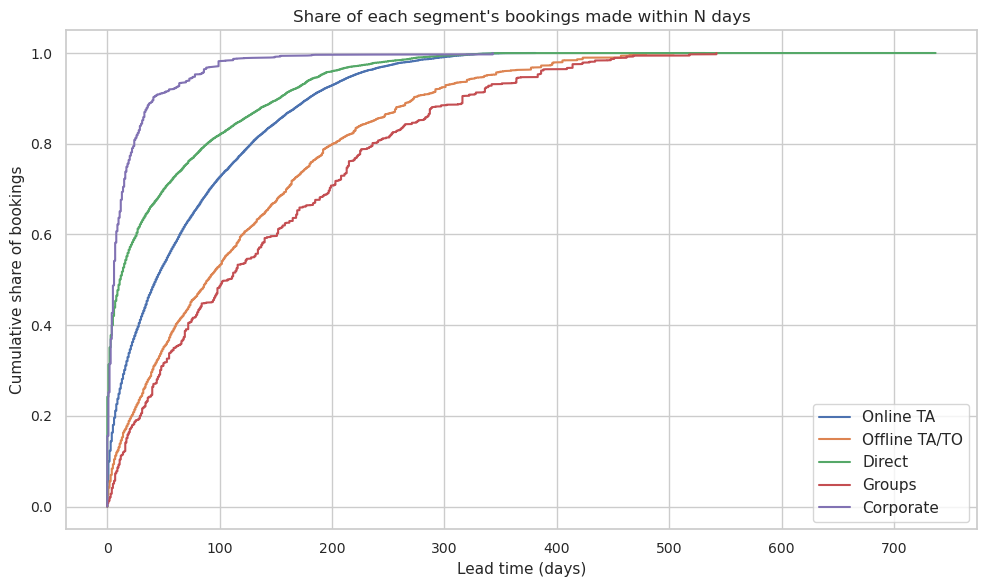

In [47]:
plt.figure(figsize=(10,6))

for lead, label in [
    (lead_online, "Online TA"),
    (lead_offline, "Offline TA/TO"),
    (lead_direct, "Direct"),
    (lead_groups, "Groups"),
    (lead_corp, "Corporate")
]:
    sorted_lt = np.sort(lead)
    cum = np.arange(1, len(sorted_lt)+1) / len(sorted_lt)
    plt.plot(sorted_lt, cum, label=label)

plt.title("Share of each segment's bookings made within N days")
plt.xlabel("Lead time (days)")
plt.ylabel("Cumulative share of bookings")
plt.legend()

plt.tight_layout()
plt.show()


In [48]:
def seg_metrics(df_seg, lead):
    return {
        "Bookings": len(df_seg),
        "Median lead": lead.median(),
        "Same-day (%)": (lead == 0).mean() * 100,
        "Within 7 days (%)": (lead <= 7).mean() * 100,
        "Over 180 days (%)": (lead > 180).mean() * 100,
        "Avg ADR": df_seg["adr"].mean()
    }

metrics_online = seg_metrics(df_online, lead_online)
metrics_offline = seg_metrics(df_offline, lead_offline)
metrics_direct = seg_metrics(df_direct, lead_direct)
metrics_groups = seg_metrics(df_groups, lead_groups)
metrics_corp = seg_metrics(df_corp, lead_corp)

metrics_online, metrics_offline, metrics_direct, metrics_groups, metrics_corp


({'Bookings': 35738,
  'Median lead': 43.0,
  'Same-day (%)': 5.52073423246964,
  'Within 7 days (%)': 21.12317421232302,
  'Over 180 days (%)': 9.740332419273603,
  'Avg ADR': 113.8630992221165},
 {'Bookings': 15908,
  'Median lead': 90.0,
  'Same-day (%)': 2.5773195876288657,
  'Within 7 days (%)': 11.220769424189088,
  'Over 180 days (%)': 24.421674629117426,
  'Avg ADR': 83.42175006286146},
 {'Bookings': 10672,
  'Median lead': 11.0,
  'Same-day (%)': 24.203523238380807,
  'Within 7 days (%)': 45.342953523238386,
  'Over 180 days (%)': 5.912668665667167,
  'Avg ADR': 113.87519958770613},
 {'Bookings': 7714,
  'Median lead': 107.0,
  'Same-day (%)': 0.77780658542909,
  'Within 7 days (%)': 7.311381903033445,
  'Over 180 days (%)': 33.57531760435572,
  'Avg ADR': 77.12454109411459},
 {'Bookings': 4303,
  'Median lead': 6.0,
  'Same-day (%)': 15.570532186846386,
  'Within 7 days (%)': 58.168719498024636,
  'Over 180 days (%)': 0.5577504066930049,
  'Avg ADR': 67.10539855914479})

In [49]:
segments_main = ["Online TA", "Offline TA/TO", "Direct", "Groups", "Corporate"]
df_seg = df_stayed[df_stayed["market_segment"].isin(segments_main)].copy()


In [50]:
median_leads = df_seg.groupby("market_segment")["lead_time_days"].median().sort_values()
median_leads


market_segment
Corporate          6.0
Direct            11.0
Online TA         43.0
Offline TA/TO     90.0
Groups           107.0
Name: lead_time_days, dtype: float64

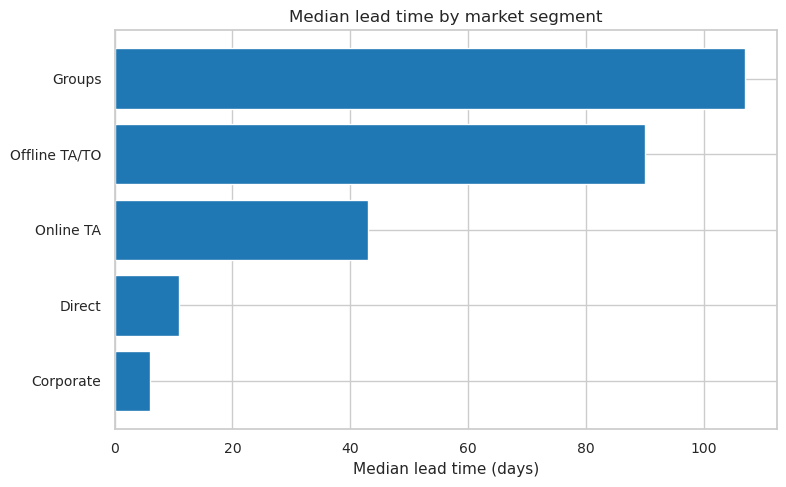

In [51]:
plt.figure(figsize=(8,5))

plt.barh(
    median_leads.index,
    median_leads.values,
    color=COLOR_BLUE
)

plt.title("Median lead time by market segment")
plt.xlabel("Median lead time (days)")

plt.tight_layout()
plt.show()


In [52]:
segment_table = df_seg.groupby("market_segment").agg(
    Bookings=("lead_time_days", "count"),
    Share=("lead_time_days", lambda x: len(x) / len(df_stayed) * 100),
    Median_lead=("lead_time_days", "median"),
    Same_day=("lead_time_days", lambda x: (x == 0).mean() * 100),
    Within_7=("lead_time_days", lambda x: (x <= 7).mean() * 100),
    Over_180=("lead_time_days", lambda x: (x > 180).mean() * 100),
    Avg_ADR=("adr", "mean")
).round(1)

segment_table


,Bookings,Share,Median_lead,Same_day,Within_7,Over_180,Avg_ADR
market_segment,,,,,,,
Corporate,4303,5.7,6.0,15.6,58.2,0.6,67.1
Direct,10672,14.2,11.0,24.2,45.3,5.9,113.9
Groups,7714,10.3,107.0,0.8,7.3,33.6,77.1
Offline TA/TO,15908,21.2,90.0,2.6,11.2,24.4,83.4
Online TA,35738,47.5,43.0,5.5,21.1,9.7,113.9


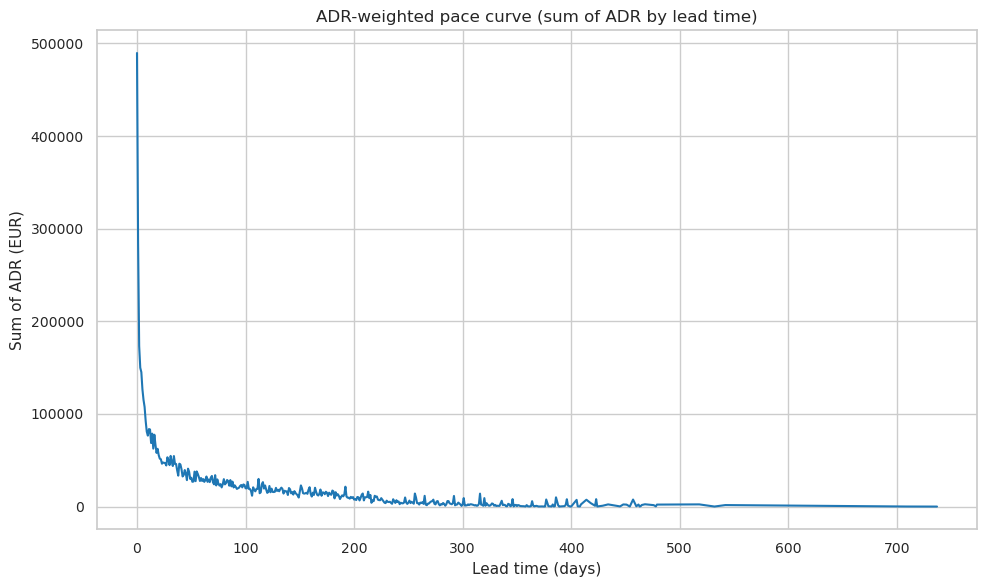

In [53]:
# ADR by Lead Time

adr_by_lead = df_stayed.groupby("lead_time_days")["adr"].sum()

plt.figure(figsize=(10,6))

plt.plot(
    adr_by_lead.index,
    adr_by_lead.values,
    color=COLOR_BLUE
)

plt.title("ADR-weighted pace curve (sum of ADR by lead time)")
plt.xlabel("Lead time (days)")
plt.ylabel("Sum of ADR (EUR)")

plt.tight_layout()
plt.show()


In [57]:
bins = [-1, 0, 7, 30, 60, 90, 180, 10000]
labels = [
    "Same day",
    "1 to 7 days",
    "8 to 30 days",
    "31 to 60 days",
    "61 to 90 days",
    "91 to 180 days",
    "181+ days"
]

df_stayed["lead_bucket"] = pd.cut(df_stayed["lead_time_days"], bins=bins, labels=labels)


In [58]:
df_stayed.columns


Index(['hotel', 'is_canceled', 'lead_time', 'arrival_date_year',
       'arrival_date_month', 'arrival_date_week_number',
       'arrival_date_day_of_month', 'stays_in_weekend_nights',
       'stays_in_week_nights', 'adults', 'children', 'babies', 'meal',
       'country', 'market_segment', 'distribution_channel',
       'is_repeated_guest', 'previous_cancellations',
       'previous_bookings_not_canceled', 'reserved_room_type',
       'assigned_room_type', 'booking_changes', 'deposit_type', 'agent',
       'company', 'days_in_waiting_list', 'customer_type', 'adr',
       'required_car_parking_spaces', 'total_of_special_requests',
       'reservation_status', 'reservation_status_date', 'arrival_date',
       'booking_date', 'lead_time_days', 'weekday', 'lead_bucket'],
      dtype='object')

In [59]:
df_city["lead_bucket"] = pd.cut(df_city["lead_time_days"], bins=bins, labels=labels)
df_resort["lead_bucket"] = pd.cut(df_resort["lead_time_days"], bins=bins, labels=labels)


C:\Users\ngosa\AppData\Local\Temp\ipykernel_34776\3494792494.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  adr_bucket_city = df_city.groupby("lead_bucket")["adr"].mean().round(1)
C:\Users\ngosa\AppData\Local\Temp\ipykernel_34776\3494792494.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  adr_bucket_resort = df_resort.groupby("lead_bucket")["adr"].mean().round(1)


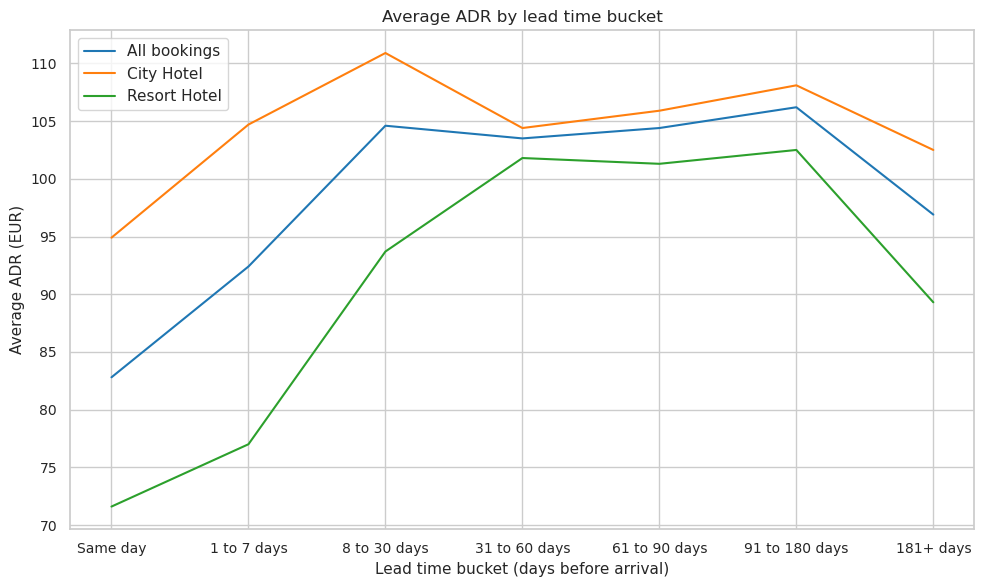

In [60]:
adr_bucket_city = df_city.groupby("lead_bucket")["adr"].mean().round(1)
adr_bucket_resort = df_resort.groupby("lead_bucket")["adr"].mean().round(1)

plt.figure(figsize=(10,6))

plt.plot(adr_bucket.index, adr_bucket.values, label="All bookings", color=COLOR_BLUE)
plt.plot(adr_bucket_city.index, adr_bucket_city.values, label="City Hotel", color=COLOR_ORANGE)
plt.plot(adr_bucket_resort.index, adr_bucket_resort.values, label="Resort Hotel", color=COLOR_GREEN)

plt.title("Average ADR by lead time bucket")
plt.xlabel("Lead time bucket (days before arrival)")
plt.ylabel("Average ADR (EUR)")
plt.legend()

plt.tight_layout()
plt.show()


In [61]:
#  Top 10 Arrival Dates

top10_dates = (
    df_stayed["arrival_date"]
    .value_counts()
    .sort_values(ascending=False)
    .head(10)
)

top10_dates


arrival_date
2015-12-05    255
2016-06-24    220
2016-05-26    213
2016-06-06    200
2017-05-25    190
2017-02-25    189
2015-10-15    188
2016-03-24    184
2015-10-02    183
2016-05-02    181
Name: count, dtype: int64

In [62]:
df_top10 = df_stayed[df_stayed["arrival_date"].isin(top10_dates.index)].copy()


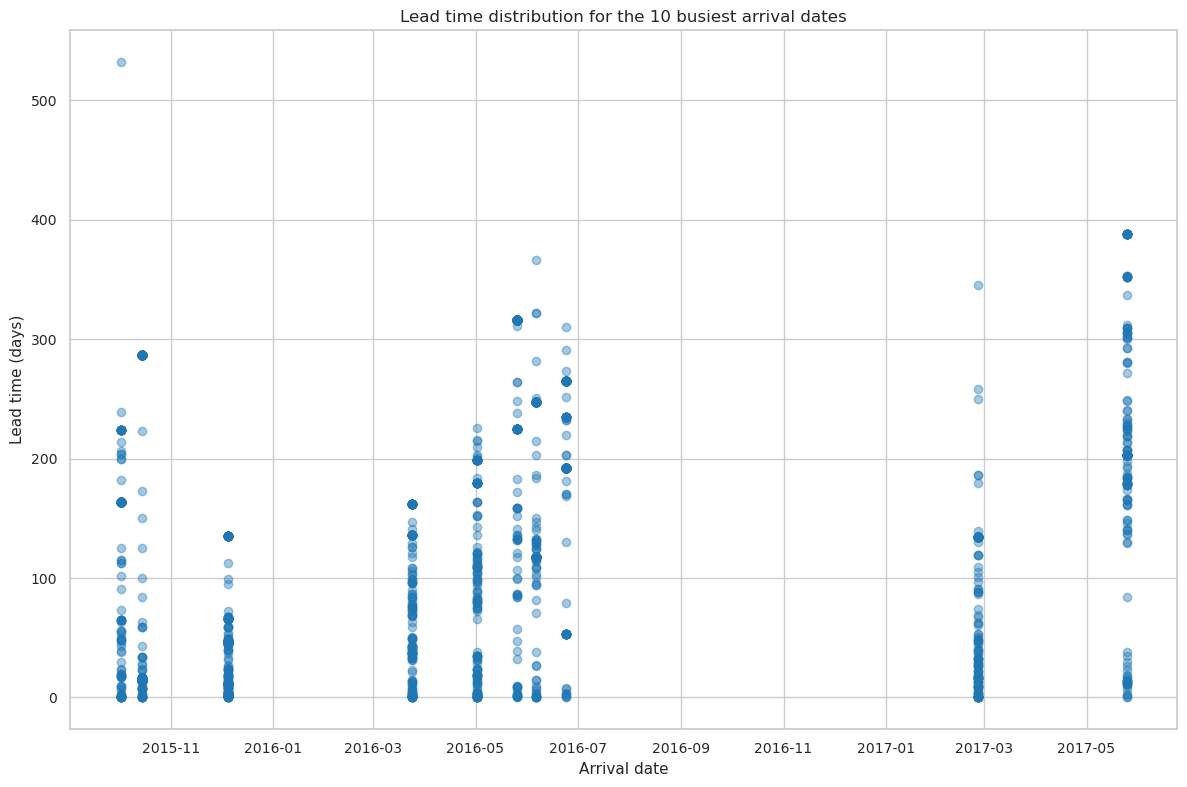

In [63]:
plt.figure(figsize=(12,8))

plt.scatter(
    df_top10["arrival_date"],
    df_top10["lead_time_days"],
    color=COLOR_BLUE,
    alpha=0.4
)

plt.title("Lead time distribution for the 10 busiest arrival dates")
plt.xlabel("Arrival date")
plt.ylabel("Lead time (days)")

plt.tight_layout()
plt.show()


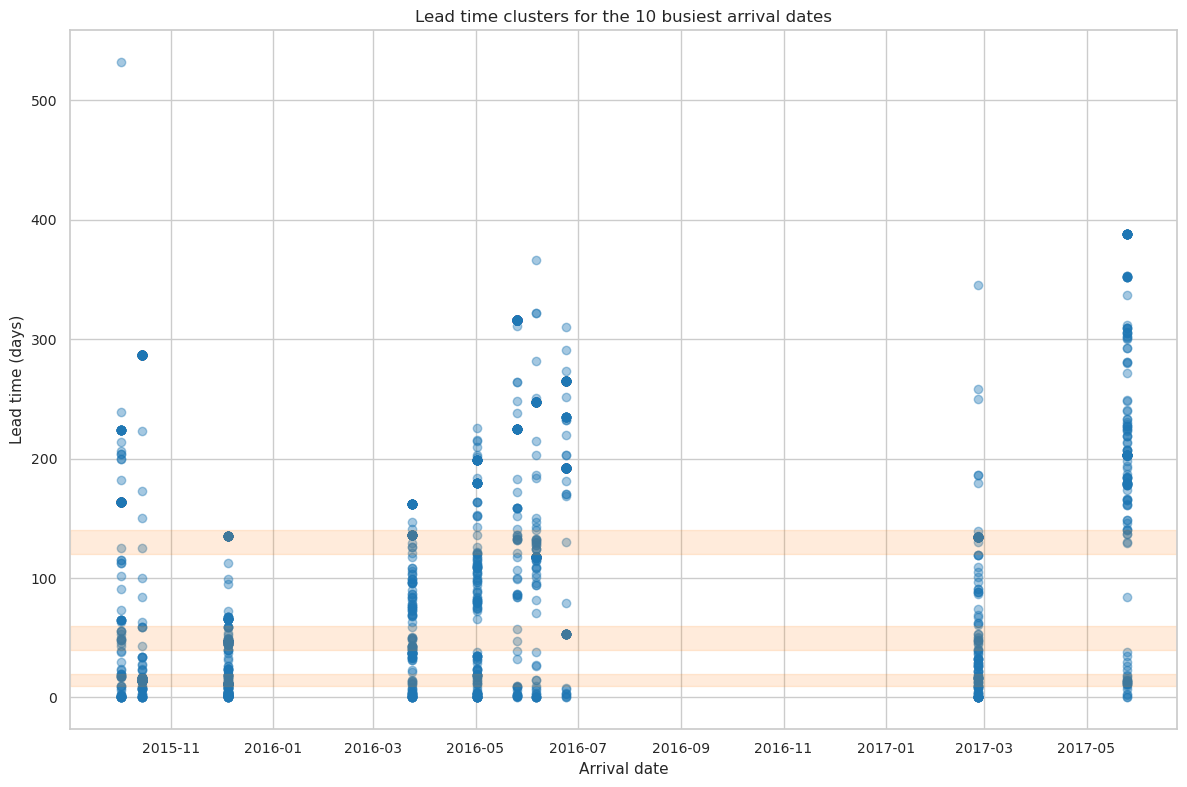

In [64]:
plt.figure(figsize=(12,8))

plt.scatter(
    df_top10["arrival_date"],
    df_top10["lead_time_days"],
    color=COLOR_BLUE,
    alpha=0.4
)

# Highlight clusters
plt.axhspan(10, 20, color=COLOR_ORANGE, alpha=0.15)
plt.axhspan(40, 60, color=COLOR_ORANGE, alpha=0.15)
plt.axhspan(120, 140, color=COLOR_ORANGE, alpha=0.15)

plt.title("Lead time clusters for the 10 busiest arrival dates")
plt.xlabel("Arrival date")
plt.ylabel("Lead time (days)")

plt.tight_layout()
plt.show()


In [65]:
top10_metrics = df_top10.groupby("arrival_date").agg(
    Bookings=("lead_time_days", "count"),
    Median_lead=("lead_time_days", "median"),
    Mean_lead=("lead_time_days", "mean"),
    Same_day=("lead_time_days", lambda x: (x == 0).mean() * 100),
    Within_7=("lead_time_days", lambda x: (x <= 7).mean() * 100),
    Over_180=("lead_time_days", lambda x: (x > 180).mean() * 100)
).round(1)

top10_metrics


,Bookings,Median_lead,Mean_lead,Same_day,Within_7,Over_180
arrival_date,,,,,,
2015-10-02,183,164.0,124.8,6.6,12.0,13.7
2015-10-15,188,34.0,138.0,4.8,10.1,44.1
2015-12-05,255,19.0,39.1,4.3,19.2,0.0
2016-03-24,184,75.5,80.0,6.0,15.8,0.0
2016-05-02,181,97.0,96.4,8.3,17.7,18.2
2016-05-26,213,316.0,244.2,0.9,5.6,77.5
2016-06-06,200,118.0,154.6,4.0,6.0,36.0
2016-06-24,220,192.0,198.7,0.9,3.2,85.0
2017-02-25,189,69.0,77.7,9.0,13.2,2.6


In [66]:
top10_dates = (
    df_stayed["arrival_date"]
    .value_counts()
    .sort_values(ascending=False)
    .head(10)
).index


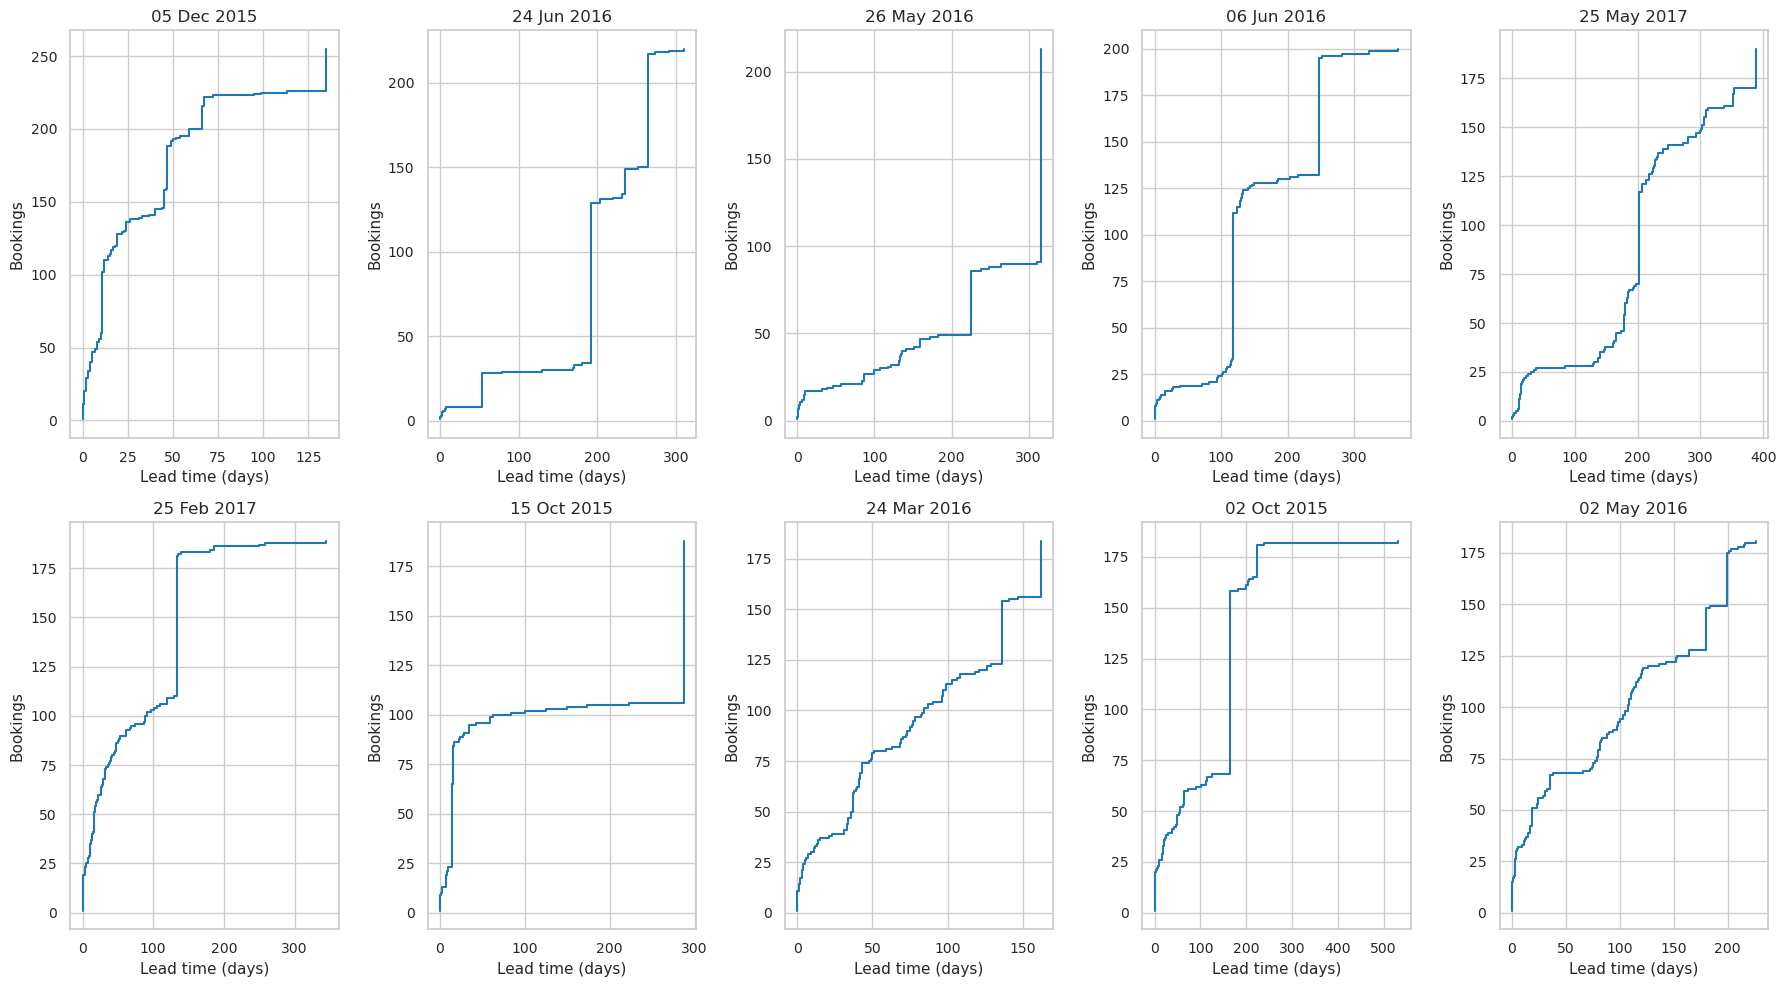

In [67]:
plt.figure(figsize=(18,10))

for i, date in enumerate(top10_dates):
    df_day = df_stayed[df_stayed["arrival_date"] == date].copy()
    df_day_sorted = df_day.sort_values("lead_time_days")
    df_day_sorted["cum_bookings"] = np.arange(1, len(df_day_sorted) + 1)

    plt.subplot(2, 5, i+1)

    plt.step(
        df_day_sorted["lead_time_days"],
        df_day_sorted["cum_bookings"],
        where="post",
        color=COLOR_BLUE
    )

    plt.title(date.strftime("%d %b %Y"))
    plt.xlabel("Lead time (days)")
    plt.ylabel("Bookings")

plt.tight_layout()
plt.show()


In [68]:
pace_metrics = df_stayed[df_stayed["arrival_date"].isin(top10_dates)].groupby("arrival_date").agg(
    Bookings=("lead_time_days", "count"),
    Median_lead=("lead_time_days", "median"),
    Mean_lead=("lead_time_days", "mean"),
    Same_day=("lead_time_days", lambda x: (x == 0).mean() * 100),
    Within_7=("lead_time_days", lambda x: (x <= 7).mean() * 100),
    Over_180=("lead_time_days", lambda x: (x > 180).mean() * 100)
).round(1)

pace_metrics


,Bookings,Median_lead,Mean_lead,Same_day,Within_7,Over_180
arrival_date,,,,,,
2015-10-02,183,164.0,124.8,6.6,12.0,13.7
2015-10-15,188,34.0,138.0,4.8,10.1,44.1
2015-12-05,255,19.0,39.1,4.3,19.2,0.0
2016-03-24,184,75.5,80.0,6.0,15.8,0.0
2016-05-02,181,97.0,96.4,8.3,17.7,18.2
2016-05-26,213,316.0,244.2,0.9,5.6,77.5
2016-06-06,200,118.0,154.6,4.0,6.0,36.0
2016-06-24,220,192.0,198.7,0.9,3.2,85.0
2017-02-25,189,69.0,77.7,9.0,13.2,2.6
